# Decision Tree (Status Negara)

## Langkah 1 - Import library

In [1]:
# Fitrya Irfan_202431073
# Langkah 1: import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Langkah 2 - Baca dataset

In [2]:
# Fitrya Irfan_202431073
# Langkah 2: baca dataset hasil scraping Praktikum 2
df = pd.read_csv("hasil_scraping_negara.csv")
print(df.head())


         Country  Total_Area_km2  Land_Area_km2  Water_Area_km2  \
0         Russia      17098246.0     16376870.0        721380.0   
1         Canada       9984670.0      9093507.0        891163.0   
2          China       9596960.0      9326410.0        270550.0   
3  United States       9525067.0      9147593.0        377424.0   
4         Brazil       8510346.0      8460415.0         55352.0   

   Water_Percent     Status  
0            4.2  Berdaulat  
1            8.9  Berdaulat  
2            2.8  Berdaulat  
3            4.0  Berdaulat  
4            0.6  Berdaulat  


## Langkah 3 - Informasi data

In [3]:
# Fitrya Irfan_202431073
# Langkah 3: informasi data
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country         254 non-null    str    
 1   Total_Area_km2  254 non-null    float64
 2   Land_Area_km2   254 non-null    float64
 3   Water_Area_km2  254 non-null    float64
 4   Water_Percent   254 non-null    float64
 5   Status          254 non-null    str    
dtypes: float64(4), str(2)
memory usage: 12.0 KB


## Langkah 4 - Deskripsi statistik

In [4]:
# Fitrya Irfan_202431073
# Langkah 4: deskripsi statistik
print(df.describe())


       Total_Area_km2  Land_Area_km2  Water_Area_km2  Water_Percent
count    2.540000e+02   2.540000e+02      254.000000     254.000000
mean     5.433723e+05   5.275836e+05    15776.279528       2.411614
std      1.702502e+06   1.637200e+06    80000.289601       5.545820
min      4.400000e-01   4.400000e-01        0.000000       0.000000
25%      8.452500e+02   8.452500e+02        0.000000       0.000000
50%      5.941500e+04   5.891700e+04      460.500000       0.700000
75%      3.536858e+05   3.474175e+05     5875.250000       2.500000
max      1.709825e+07   1.637687e+07   891163.000000      66.700000


## Langkah 5 - Cek data kosong

In [5]:
# Fitrya Irfan_202431073
# Langkah 5: cek data kosong
print(df.isna().sum())


Country           0
Total_Area_km2    0
Land_Area_km2     0
Water_Area_km2    0
Water_Percent     0
Status            0
dtype: int64


## Langkah 6 - Isi unik kolom target

In [6]:
# Fitrya Irfan_202431073
# Langkah 6: isi unik kolom target
print(df["Status"].unique())
print(df["Status"].value_counts())
# Arti tiap kelas:
# Berdaulat  = negara berdaulat (tidak berada di bawah negara lain)
# Dependensi = wilayah dependensi / bagian dari negara induk, contoh: Greenland (Denmark)


<StringArray>
['Berdaulat', 'Dependensi']
Length: 2, dtype: str
Status
Berdaulat     203
Dependensi     51
Name: count, dtype: int64


## Langkah 7 - Pisahkan fitur x dan target y

In [7]:
# Fitrya Irfan_202431073
# Langkah 7: pisahkan fitur x dan target y (kolom Country hanya nama, bukan fitur)
x = df.drop(columns=["Country", "Status"])
y = df["Status"]
print("Fitur x:", list(x.columns))
print("Ukuran x:", x.shape, "| Ukuran y:", y.shape)


Fitur x: ['Total_Area_km2', 'Land_Area_km2', 'Water_Area_km2', 'Water_Percent']
Ukuran x: (254, 4) | Ukuran y: (254,)


## Langkah 8 - Ubah x dan y menjadi array angka

In [8]:
# Fitrya Irfan_202431073
# Langkah 8: ubah x dan y menjadi array angka
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)          # target teks -> angka
print("Kelas:", list(le.classes_), "->", list(range(len(le.classes_))))

x = np.array(x, dtype="float64")
y = np.array(y, dtype="int64")
print(x.dtype, y.dtype)


Kelas: ['Berdaulat', 'Dependensi'] -> [0, 1]
float64 int64


## Langkah 9 - Bagi data latih dan uji

In [9]:
# Fitrya Irfan_202431073
# Langkah 9: bagi data latih dan uji (test_size = 0.3, random_state = 0)
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)
print("Data latih:", len(x_train), "| Data uji:", len(x_test))


Data latih: 177 | Data uji: 77


## Langkah 10 - Buat dan latih model DecisionTreeClassifier

In [10]:
# Fitrya Irfan_202431073
# Langkah 10: buat model dan latih (fit)
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=0)
model.fit(x_train, y_train)
print("Model berhasil dilatih")
print("Kedalaman pohon:", model.get_depth(), "| Jumlah daun:", model.get_n_leaves())


Model berhasil dilatih
Kedalaman pohon: 13 | Jumlah daun: 31


## Langkah 11 - Visualisasi pohon

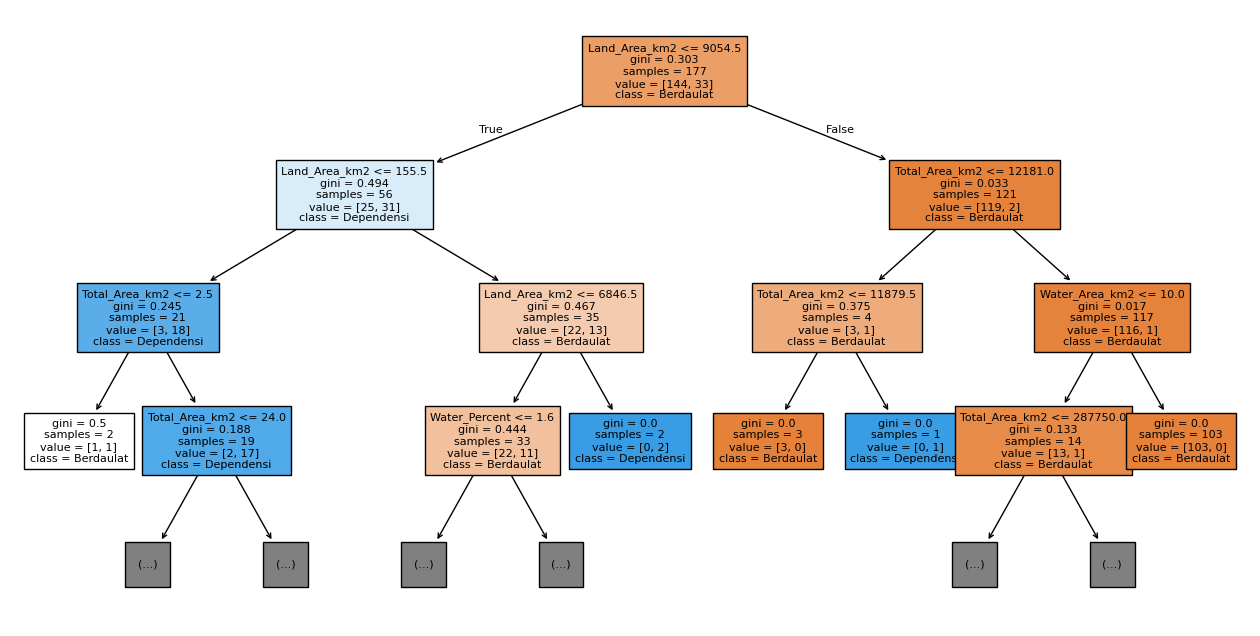

In [11]:
# Fitrya Irfan_202431073
# Langkah 11: visualisasi pohon (ditampilkan sampai kedalaman 3 agar terbaca)
from sklearn import tree

plt.figure(figsize=(16, 8))
tree.plot_tree(model, max_depth=3, filled=True, fontsize=8,
               feature_names=["Total_Area_km2", "Land_Area_km2", "Water_Area_km2", "Water_Percent"],
               class_names=list(le.classes_))
plt.show()


## Langkah 12 - Uji dengan 1 data baru

In [12]:
# Fitrya Irfan_202431073
# Langkah 12: uji dengan 1 data baru
# urutan: Total_Area_km2, Land_Area_km2, Water_Area_km2, Water_Percent
data_baru = np.array([[50000.0, 48500.0, 1500.0, 3.0]])
hasil = model.predict(data_baru)
print("Hasil prediksi (angka):", hasil[0])
print("Hasil prediksi (kelas):", le.inverse_transform(hasil)[0])


Hasil prediksi (angka): 0
Hasil prediksi (kelas): Berdaulat


## Langkah 13 - Hitung akurasi

In [13]:
# Fitrya Irfan_202431073
# Langkah 13: hitung akurasi
from sklearn.metrics import accuracy_score

y_pred = model.predict(x_test)
print("Akurasi:", accuracy_score(y_test, y_pred))


Akurasi: 0.8181818181818182


## Langkah 14 - Classification report

In [14]:
# Fitrya Irfan_202431073
# Langkah 14: classification report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=list(le.classes_)))


              precision    recall  f1-score   support

   Berdaulat       0.84      0.95      0.89        59
  Dependensi       0.70      0.39      0.50        18

    accuracy                           0.82        77
   macro avg       0.77      0.67      0.69        77
weighted avg       0.80      0.82      0.80        77

